In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

In [59]:
"""Download Disney stock price data"""

start_date = "2010-01-01"
end_date = "2015-12-31"
ticker = "DIS"

data = yf.download(ticker, start=start_date, end=end_date, actions=True)
data.to_csv("/Users/sasuvanska/Library/CloudStorage/OneDrive-Personal/Project/Code/Project 1/dis_data.csv")

data = open("DIS_data", mode="w")
    
if data != None:
    print("Data downloaded")
    
data.close


[*********************100%***********************]  1 of 1 completed

Data downloaded


<function TextIOWrapper.close()>

In [63]:
"""Open stock data"""
df = pd.read_csv("DIS_data.csv", header=0)
df.drop(df.index[0], inplace=True) 

print(df)

           Price               Close Dividends                High  \
1           Date                 NaN       NaN                 NaN   
2     2010-01-04  27.083698272705078       0.0  27.657970903387408   
3     2010-01-05  27.016136169433594       0.0  27.159704323320167   
4     2010-01-06  26.872573852539062       0.0  27.024587414472016   
5     2010-01-07  26.881019592285156       0.0   26.90635572321299   
...          ...                 ...       ...                 ...   
1506  2015-12-23   96.55867004394531       0.0   98.09541311796018   
1507  2015-12-24   96.83309173583984       0.0   97.54657834942401   
1508  2015-12-28   98.10455322265625       0.0   98.97354181165566   
1509  2015-12-29   97.94903564453125       0.0   98.82717332603865   
1510  2015-12-30   97.27214813232422       0.0   98.06796380803816   

                     Low                Open Stock Splits    Volume  
1                    NaN                 NaN          NaN       NaN  
2     26.9147956000

/var/folders/mm/tdvw9cl53xd47_6x89257dvw0000gn/T/ipykernel_60708/3482580559.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(df.index[0], inplace=True)


In [64]:
"""Rename columns"""
print(df.columns.tolist())
df = df.rename(columns={'Price': 'date'})
# Delete the double header row
df = df.drop(df.index[0])
df = df.rename(columns={'date': 'date', 'Open': 'open', 'High': 'high', 'Low': 'low', 'Close': 'close', 'Volume': 'volume', 'Dividends': 'dividends', 'Stock Splits': 'splits'})
print(df)

['Price', 'Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']
            date               close dividends                high  \
2     2010-01-04  27.083698272705078       0.0  27.657970903387408   
3     2010-01-05  27.016136169433594       0.0  27.159704323320167   
4     2010-01-06  26.872573852539062       0.0  27.024587414472016   
5     2010-01-07  26.881019592285156       0.0   26.90635572321299   
6     2010-01-08   26.92324447631836       0.0    26.9739167374399   
...          ...                 ...       ...                 ...   
1506  2015-12-23   96.55867004394531       0.0   98.09541311796018   
1507  2015-12-24   96.83309173583984       0.0   97.54657834942401   
1508  2015-12-28   98.10455322265625       0.0   98.97354181165566   
1509  2015-12-29   97.94903564453125       0.0   98.82717332603865   
1510  2015-12-30   97.27214813232422       0.0   98.06796380803816   

                     low                open splits    volume  
2     26.91479

In [66]:
"""Check is there duplicate dates"""
# Check the data type of the 'date' column
print(df['date'].dtype)
# Convert the 'date' column to datetime type
df['date'] = pd.to_datetime(df['date'])
for index, row in df.iterrows():
    if df['date'].duplicated().any():
        print(f"Duplicate date found: {row['date']}")

str


In [68]:
"""Check the price"""
# Check the data type of the 'price' column
print(df['close'].dtype)
# Convert the 'price' column to numeric type
df['close'] = pd.to_numeric(df['close'])
for index, row in df.iterrows():
    if row['close'] <= 0:
        print(f"Invalid price on {row['date']}: {row['close']}")
    if pd.isnull(row['close']):
        print(f"Missing price on {row['date']}")

str


In [69]:
"""Check the dividends"""
# Check the data type of the 'dividends' column
print(df['dividends'].dtype)
# Convert the 'dividends' column to numeric type
df['dividends'] = pd.to_numeric(df['dividends'])

df['dividends'] = df['dividends'].fillna(0.0)

for index, row in df.iterrows():
    if row['dividends'] != 0.0:
        print(f"Dividend on {row['date']}: {row['dividends']}")

str
Dividend on 2010-12-09 00:00:00: 0.4
Dividend on 2011-12-14 00:00:00: 0.6
Dividend on 2012-12-06 00:00:00: 0.75
Dividend on 2013-12-12 00:00:00: 0.86
Dividend on 2014-12-11 00:00:00: 1.15
Dividend on 2015-07-01 00:00:00: 0.66
Dividend on 2015-12-10 00:00:00: 0.71


In [71]:
"""Check the high price"""
# Check the data type of the 'high' column
print(df['high'].dtype)
# Convert the 'high' column to numeric type
df['high'] = pd.to_numeric(df['high'])
for index, row in df.iterrows():
    if row['high'] <= 0:
        print(f"Invalid high price on {row['date']}: {row['high']}")
    if pd.isnull(row['high']):
        print(f"Missing high price on {row['date']}")

str


In [73]:
"""Check the low price"""
# Check the data type of the 'low' column
print(df['low'].dtype)
# Convert the 'low' column to numeric type
df['low'] = pd.to_numeric(df['low'])
for index, row in df.iterrows():
    if row['low'] <= 0:
        print(f"Invalid low price on {row['date']}: {row['low']}")
    if pd.isnull(row['low']):
        print(f"Missing low price on {row['date']}")

str


In [75]:
"""Check the open price"""
# Check the data type of the 'open' column
print(df['open'].dtype)
# Convert the 'open' column to numeric type
df['open'] = pd.to_numeric(df['open'])
for index, row in df.iterrows():
    if row['open'] <= 0:
        print(f"Invalid open price on {row['date']}: {row['open']}")
    if pd.isnull(row['open']):
        print(f"Missing open price on {row['date']}")

str


In [77]:
"""Check stock splits"""
# Check the data type of the 'splits' column
print(df['splits'].dtype)
# Convert the 'splits' column to numeric type
df['splits'] = pd.to_numeric(df['splits'])

for index, row in df.iterrows():
    if row['splits'] != 0.0:
        print(f"Stock split on {row['Date']}: {row['Splits']}")
    

str


In [79]:
"""Check the volume"""
# Check the data type of the 'volume' column
print(df['volume'].dtype)
# Change the data type of the 'volume' column to numeric
df['volume'] = pd.to_numeric(df['volume'])

for index, row in df.iterrows():
    if row['volume'] <= 0:
        print(f"Invalid volume on {row['date']}: {row['volume']}")
    if pd.isnull(row['volume']):
        print(f"Missing volume on {row['date']}")

str


In [84]:
"""Add the adjusted price column"""
dividends = df[df['dividends'] != 0.0]
# Create column of adjustment factors, initialized to 1.0
df['adj_factor'] = 1.0

for index, row in df.iterrows():
    if row['dividends'] != 0.0:
        df.loc[row.name, 'adj_factor'] = (row['low'] - row['dividends']) / row['close']

df['adj_factor'] = df['adj_factor'].shift(-1).fillna(1.0)

df['adj_price'] = df['close'] * df['adj_factor'].cumprod()

print(df)

           date      close  dividends       high        low       open  \
2    2010-01-04  27.083698        0.0  27.657971  26.914796  27.446841   
3    2010-01-05  27.016136        0.0  27.159704  26.771227  27.083698   
4    2010-01-06  26.872574        0.0  27.024587  26.754342  26.940135   
5    2010-01-07  26.881020        0.0  26.906356  26.636110  26.830349   
6    2010-01-08  26.923244        0.0  26.973917  26.627664  26.737451   
...         ...        ...        ...        ...        ...        ...   
1506 2015-12-23  96.558670        0.0  98.095413  95.406118  98.067972   
1507 2015-12-24  96.833092        0.0  97.546578  96.101307  96.229368   
1508 2015-12-28  98.104553        0.0  98.973542  97.263005  97.418507   
1509 2015-12-29  97.949036        0.0  98.827173  97.372753  98.680814   
1510 2015-12-30  97.272148        0.0  98.067964  97.189826  97.775251   

      splits    volume  adj_factor  adj_price  
2        0.0  13700400         1.0  27.083698  
3        0.0  1

In [86]:
"""Check the adjusted factor dates"""
for index, row in df.iterrows():
    if row['adj_factor'] != 1.0:
        print(f"Adjustment factor on {row['date']}: {row['adj_factor']}")
for index, row in df.iterrows():
    if row['dividends'] != 0.0:
        print(f"Dividend on {row['date']}: {row['dividends']}")

Adjustment factor on 2010-12-08 00:00:00: 0.980987438983197
Adjustment factor on 2011-12-13 00:00:00: 0.9792044465511903
Adjustment factor on 2012-12-05 00:00:00: 0.9724643945577427
Adjustment factor on 2013-12-11 00:00:00: 0.9742382511271396
Adjustment factor on 2014-12-10 00:00:00: 0.974249387900455
Adjustment factor on 2015-06-30 00:00:00: 0.9868309539152317
Adjustment factor on 2015-12-09 00:00:00: 0.9876653022614534
Dividend on 2010-12-09 00:00:00: 0.4
Dividend on 2011-12-14 00:00:00: 0.6
Dividend on 2012-12-06 00:00:00: 0.75
Dividend on 2013-12-12 00:00:00: 0.86
Dividend on 2014-12-11 00:00:00: 1.15
Dividend on 2015-07-01 00:00:00: 0.66
Dividend on 2015-12-10 00:00:00: 0.71


In [113]:
"""Add the returns column"""
df = df.sort_values(by='date', ascending=True)  
df['returns'] = df['adj_price'].pct_change()
df['log_returns'] = np.log(df['adj_price'] / df['adj_price'].shift(1))

print(df)

           date      close  dividends       high        low       open  \
2    2010-01-04  27.083698        0.0  27.657971  26.914796  27.446841   
3    2010-01-05  27.016136        0.0  27.159704  26.771227  27.083698   
4    2010-01-06  26.872574        0.0  27.024587  26.754342  26.940135   
5    2010-01-07  26.881020        0.0  26.906356  26.636110  26.830349   
6    2010-01-08  26.923244        0.0  26.973917  26.627664  26.737451   
...         ...        ...        ...        ...        ...        ...   
1506 2015-12-23  96.558670        0.0  98.095413  95.406118  98.067972   
1507 2015-12-24  96.833092        0.0  97.546578  96.101307  96.229368   
1508 2015-12-28  98.104553        0.0  98.973542  97.263005  97.418507   
1509 2015-12-29  97.949036        0.0  98.827173  97.372753  98.680814   
1510 2015-12-30  97.272148        0.0  98.067964  97.189826  97.775251   

      splits    volume  adj_factor  adj_price   returns  log_returns  \
2        0.0  13700400         1.0  27.

In [116]:
if df['log_returns'] == 0.0:
    df['log_returns'] = df['log_returns'].replace(0, 1e-6)

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.item(), a.any() or a.all().

In [ ]:
"""Z-scores"""
df['rolling_mad'] = df['log_returns'].shift(1).rolling(window=60).apply(lambda x: np.median(np.abs(x - np.median(x))))
df['z_score'] = (df['log_returns'] - df['log_returns'].shift(1).rolling(window=60).median()) / (1.4826 * df['rolling_mad'])
outliers = df[df['z_score'].abs() > 8]

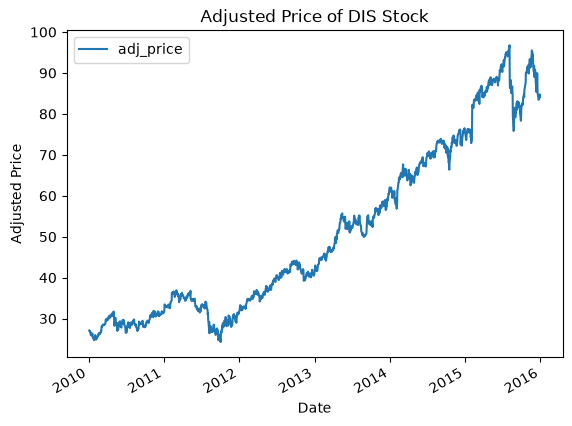

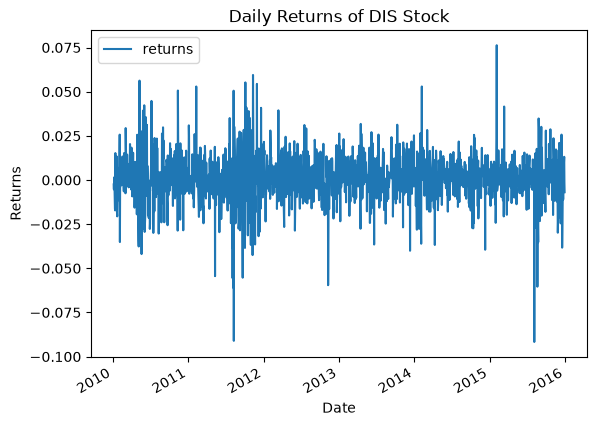

In [ ]:
fig1 = df.plot(x='date', y='adj_price', title='Adjusted Price of DIS Stock', ylabel='Adjusted Price', xlabel='Date')
fig2 = df.plot(x='date', y='returns', title='Daily Returns of DIS Stock', ylabel='Returns', xlabel='Date')
plt.show(fig1)
plt.show(fig2)